In [1]:
from astropy.io import ascii
from astropy.table import unique

In [2]:
qso = Table.read(ddir + 'alr53/BALs_nonBALs/mastertable_AmyR_extended2_LDR1_210210.fits')
CIVm = np.zeros(len(qso['CIV_EW_eun']), 'bool')
CIVm[np.where((qso['CIV_EW_eun']>10.) & (qso['CIV_blue_eun']>-1200) & (qso['CIV_blue_eun']<7500) & 
              (qso['chisqr']<2.) & (qso['Ngood_CIV']>0))[0]] = 1
CIVm[qso['AlIII_BI'] > 0] = 0
CIVm[qso['FeLoBAL']] = 0

CIVm[np.log10(qso['CIV_EW_eun'])<-0.00023077 * qso['CIV_blue_eun'] + 1.3231] = 0

good = np.zeros(len(qso['BI_BI']), 'bool')
good[np.where((qso['chisqr'] <= 2.) & (CIVm==1))[0]] = 1
good[qso['AlIII_BI'] > 0] = 0

inds = (qso['BI_BI'] > 0) * (qso['catalogue'] == 1) * good * (qso['CIV_EW'] > 10) #* (qso['SNRpaul'] >= 10)

/var/folders/9t/6j8p7z0x583cjfdb_xn5mctw0000gn/T/ipykernel_64436/1733021833.py:8: RuntimeWarning: divide by zero encountered in log10
  CIVm[np.log10(qso['CIV_EW_eun'])<-0.00023077 * qso['CIV_blue_eun'] + 1.3231] = 0
/var/folders/9t/6j8p7z0x583cjfdb_xn5mctw0000gn/T/ipykernel_64436/1733021833.py:8: RuntimeWarning: invalid value encountered in log10
  CIVm[np.log10(qso['CIV_EW_eun'])<-0.00023077 * qso['CIV_blue_eun'] + 1.3231] = 0


In [3]:
speeds = ascii.read('DR16EHVO_DR14RankineInfo_wEHVOspeed_corrected.csv', format='commented_header')
speeds

SDSS_NAME0,plate_parentDR16,mjd_parentDR16,fiber_parentDR16,z0,CIV_blue0,CIV_EW0,HeII_EW0,BAL0,nBAL0,BI_BI0,BI_VMAX0,BI_VMIN0,BI_FMIN0,CIVdist0,SNR0,log_MBH_Ran0,log_Lbol_Ran0,log_Redd_Ran0,log_MBH_Rak140,log_MBH_err_Rak140,Q_MBH_Rak140,og_Lbol_Rak140,Q_Lbol_Rak140,log_Redd_Rak140,Q_Redd_Rak140,BI_CIV_Rak140,BI_CIV_err_Rak140,BAL_flag_Rak140,EHVO_vmin,col30,_1,_2,EHVO_vmax,_3,_4,_5
str18,int64,int64,int64,float64,float64,float64,float64,str5,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,int64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64
004300.26+045718.6,4419,55867,178,2.362696,1717.537388,23.87619413,0.102600544,False,True,0.0,0.0,0.0,0.0,0.754830495,17.9933109,9.654579531,47.36237263,-0.3915647,9.022771821,0.14004676,0,46.94924456,0,-0.21340635,0,0.0,0.0,-999,-35496.14147,--,--,--,-39572.99625,--,--,--
002107.48+090626.6,4538,55860,660,2.32407,2407.101533,32.392288,0.07270201,False,True,0.0,0.0,0.0,0.0,0.774615135,14.5624456,9.136222895,46.8988501,-0.336730593,8.90705128,0.189414366,0,46.73084168,0,-0.316088689,0,0.0,0.0,-999,-35496.14147,--,--,--,-43319.0206,--,--,--
010447.39+101031.6,4663,55893,248,2.36838,750.8236203,13.5077869,-999.0,False,True,0.0,0.0,0.0,0.0,0.753987159,21.0447807,9.697789038,47.34991382,-0.447233014,9.521223506,0.043417695,0,47.06884114,0,-0.592261451,0,0.0,0.0,-999,-33637.26727,--,--,--,-37176.62098,--,--,--
010645.66+114123.8,4663,55893,854,3.1137,2874.832431,26.92966755,0.06049445,False,True,0.0,0.0,0.0,0.0,0.866828617,16.8122635,9.505063062,47.29247533,-0.311945527,10.00352196,0.030540942,0,47.19090105,0,-0.952499995,0,0.0,0.0,-999,-37822.46963,--,--,--,-41349.33362,--,--,--
224120.02+164100.8,5039,56220,625,2.404823,3901.492319,16.94558464,0.026129214,False,True,0.0,0.0,0.0,0.0,1.06556339,26.0518131,9.416456218,47.12950628,-0.386307733,10.25900362,0.098107175,10,47.20412264,0,-1.194760058,10,0.0,0.0,-999,-36857.85529,--,--,--,-40116.74668,--,--,--
085824.80+265903.0,5179,55957,836,2.488067,4962.039367,9.356853628,-999.0,False,True,0.0,0.0,0.0,0.0,1.220924762,20.743845,9.389990936,47.05638428,-0.432964455,10.69358002,0.111876721,11,47.07987111,0,-1.753588,11,0.0,0.0,0,-46367.17191,--,--,--,-48856.84528,--,--,--
165542.60+381338.3,5187,56074,92,1.94424,5420.614085,14.20325546,0.0,False,True,0.0,0.0,0.0,0.0,1.280980671,37.5447464,9.529406018,47.47054574,-0.158218075,10.00396394,0.040640183,10,47.49718037,0,-0.646662656,10,0.0,0.0,0,-36372.1932,--,--,--,-45583.97917,--,--,--
162122.54+075808.4,5212,56016,348,2.140198,2297.16685,35.04136602,0.013943411,True,False,1897.710206,24989.99739,12064.01448,0.368701631,0.747762952,29.242218,9.523730153,47.26173079,-0.361357156,9.654257383,0.025077578,-999,47.14671017,0,-0.647426296,-999,1885.9146,14.463399,1,-35942.09495,--,--,--,-38728.30842,--,--,--
085119.10+134652.5,5288,55865,958,3.20193,2283.503237,34.63947103,0.157632026,True,False,844.0720349,5029.013958,3027.531186,0.712338019,0.748408034,20.0534267,9.489107335,47.33738471,-0.251080419,8.769272884,0.108341463,-999,47.2929415,0,0.383789532,-999,83.96163,0.12043419,1,-35942.09495,--,--,--,-39956.0373,--,--,--


In [4]:
len(unique(speeds['SDSS_NAME0', 'plate_parentDR16']))

69

In [5]:
speedsdr9 = ascii.read('DR9EHVO_DR14RankineInfo_wEHVOspeed_corrected.csv', format='commented_header')
speedsdr9['dr9'] = np.ones(len(speedsdr9), bool)
speedsdr9

SDSS_NAME0,plate_parentDR16,mjd_parentDR16,fiber_parentDR16,z0,CIV_blue0,CIV_EW0,HeII_EW0,BAL0,nBAL0,BI_BI0,BI_VMAX0,BI_VMIN0,BI_FMIN0,CIVdist0,SNR0,log_MBH_Ran0,log_Lbol_Ran0,log_Redd_Ran0,log_MBH_Rak140,log_MBH_err_Rak140,Q_MBH_Rak140,og_Lbol_Rak140,Q_Lbol_Rak140,log_Redd_Rak140,Q_Redd_Rak140,BI_CIV_Rak140,BI_CIV_err_Rak140,BAL_flag_Rak140,EHVO_vmin,col30,_1,EHVO_vmax,_2,_3,dr9
str18,int64,int64,int64,float64,float64,float64,float64,str5,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,int64,float64,float64,int64,float64,float64,float64,float64,float64,float64,bool
071843.50+391720.3,3655,55240,388,2.6303,1155.186616,39.3734527,1.133875956,False,True,0.0,0.0,0.0,0.0,0.6147956338,20.0458221,9.498293895,46.99456573,-0.6030859568,9.236235954,0.1032901947,0,46.99888194,0,-0.3772331009,0,0.0,0.0,-999,-38815.9793,--,--,-43492.5284,--,--,True
092125.97-023411.9,3766,55213,46,2.791618,1562.975042,48.01099531,1.660090768,False,True,0.0,0.0,0.0,0.0,0.6231893513,14.6886797,8.90057334,46.74600219,-0.253928949,8.702048155,0.09652516803,0,46.72185277,0,-0.1200744727,0,0.0,0.0,-999,-35879.5974,--,--,-42398.0395,--,--,True
083304.73+415331.3,3808,55513,892,2.35019,5708.549104,7.809153859,-999.0,False,True,0.0,0.0,0.0,0.0,1.319700537,12.3759327,9.08057185,46.77455394,-0.4053757115,9.485997872,0.1804413635,10,46.58363209,0,-1.04224487,10,0.0,0.0,0,-46683.9349,--,--,-59993.3305,--,--,True
085825.71+005006.7,3815,55537,910,2.86171,1317.373843,39.57260538,1.031165367,False,True,0.0,0.0,0.0,0.0,0.6302345884,14.2673941,9.542825672,47.08245378,-0.5597296849,9.56975866,0.04144721634,0,47.0324538,0,-0.6771839439,0,0.0,0.0,0,-35712.7284,--,--,-38025.934,--,--,True
094258.03+005359.5,3826,55563,860,2.46644,1984.124065,26.43123684,0.06542797604,False,True,0.0,0.0,0.0,0.0,0.7647105638,16.3180256,9.374553065,46.79577401,-0.6781368534,9.508660798,0.03678081945,0,46.92593626,0,-0.7226036234,0,0.0,0.0,-999,-35374.9952,--,--,-39115.5318,--,--,True
120609.69+004522.6,3844,55321,920,2.708162,4661.038755,11.40821838,0.02282897945,False,True,0.0,0.0,0.0,0.0,1.180927111,29.7529774,9.484419762,47.52068607,-0.06309149129,9.857788646,0.1668102198,-999,47.50318829,0,-0.4944794377,-999,0.0,0.0,1,-32903.1079,-39912.9309,-55062.3467,-57528.181,-35425.8465,-49234.4428,True
135203.03+333938.3,3861,55274,582,3.08246,2236.497027,14.48970857,0.3686978413,False,True,0.0,0.0,0.0,0.0,0.87914084,13.5268831,9.45178001,46.93276438,-0.6183734312,9.474793586,0.3052473236,0,46.81339124,0,-0.801281433,0,0.0,0.0,0,-36626.491,--,--,-41651.0697,--,--,True
150339.76+183423.9,3957,55664,568,2.1845,4218.40553,16.56883479,-999.0,False,True,0.0,0.0,0.0,0.0,1.122059839,23.3491211,9.322360538,47.35466088,-0.06705745531,9.635250991,0.04583989426,10,47.10591968,0,-0.6692104026,10,0.0,0.0,0,-37523.927,-47742.8322,-57050.8863,-59111.9448,-39562.0438,-48953.963,True
133752.36-011924.7,4046,55605,85,2.821769,2895.068747,21.30619281,0.08260076329,True,False,1172.5912,24989.99739,21009.91031,0.5652992166,0.904084007,13.458786,9.560583969,46.93788658,-0.722055187,9.90816605,0.085735422,-999,46.86733107,0,-1.18071407,-999,762.081,19.169685,1,-38423.4239,--,--,-42221.7875,--,--,True


In [6]:
len(unique(speedsdr9['SDSS_NAME0', 'plate_parentDR16']))

31

In [7]:
from astropy.table import vstack, unique

In [8]:
speeds = vstack((speeds, speedsdr9))
speeds['dr9'][speeds['dr9'].mask] = False
speeds

SDSS_NAME0,plate_parentDR16,mjd_parentDR16,fiber_parentDR16,z0,CIV_blue0,CIV_EW0,HeII_EW0,BAL0,nBAL0,BI_BI0,BI_VMAX0,BI_VMIN0,BI_FMIN0,CIVdist0,SNR0,log_MBH_Ran0,log_Lbol_Ran0,log_Redd_Ran0,log_MBH_Rak140,log_MBH_err_Rak140,Q_MBH_Rak140,og_Lbol_Rak140,Q_Lbol_Rak140,log_Redd_Rak140,Q_Redd_Rak140,BI_CIV_Rak140,BI_CIV_err_Rak140,BAL_flag_Rak140,EHVO_vmin,col30,_1,_2,EHVO_vmax,_3,_4,_5,dr9
str18,int64,int64,int64,float64,float64,float64,float64,str5,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,int64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,bool
004300.26+045718.6,4419,55867,178,2.362696,1717.537388,23.87619413,0.102600544,False,True,0.0,0.0,0.0,0.0,0.754830495,17.9933109,9.654579531,47.36237263,-0.3915647,9.022771821,0.14004676,0,46.94924456,0,-0.21340635,0,0.0,0.0,-999,-35496.14147,--,--,--,-39572.99625,--,--,--,False
002107.48+090626.6,4538,55860,660,2.32407,2407.101533,32.392288,0.07270201,False,True,0.0,0.0,0.0,0.0,0.774615135,14.5624456,9.136222895,46.8988501,-0.336730593,8.90705128,0.189414366,0,46.73084168,0,-0.316088689,0,0.0,0.0,-999,-35496.14147,--,--,--,-43319.0206,--,--,--,False
010447.39+101031.6,4663,55893,248,2.36838,750.8236203,13.5077869,-999.0,False,True,0.0,0.0,0.0,0.0,0.753987159,21.0447807,9.697789038,47.34991382,-0.447233014,9.521223506,0.043417695,0,47.06884114,0,-0.592261451,0,0.0,0.0,-999,-33637.26727,--,--,--,-37176.62098,--,--,--,False
010645.66+114123.8,4663,55893,854,3.1137,2874.832431,26.92966755,0.06049445,False,True,0.0,0.0,0.0,0.0,0.866828617,16.8122635,9.505063062,47.29247533,-0.311945527,10.00352196,0.030540942,0,47.19090105,0,-0.952499995,0,0.0,0.0,-999,-37822.46963,--,--,--,-41349.33362,--,--,--,False
224120.02+164100.8,5039,56220,625,2.404823,3901.492319,16.94558464,0.026129214,False,True,0.0,0.0,0.0,0.0,1.06556339,26.0518131,9.416456218,47.12950628,-0.386307733,10.25900362,0.098107175,10,47.20412264,0,-1.194760058,10,0.0,0.0,-999,-36857.85529,--,--,--,-40116.74668,--,--,--,False
085824.80+265903.0,5179,55957,836,2.488067,4962.039367,9.356853628,-999.0,False,True,0.0,0.0,0.0,0.0,1.220924762,20.743845,9.389990936,47.05638428,-0.432964455,10.69358002,0.111876721,11,47.07987111,0,-1.753588,11,0.0,0.0,0,-46367.17191,--,--,--,-48856.84528,--,--,--,False
165542.60+381338.3,5187,56074,92,1.94424,5420.614085,14.20325546,0.0,False,True,0.0,0.0,0.0,0.0,1.280980671,37.5447464,9.529406018,47.47054574,-0.158218075,10.00396394,0.040640183,10,47.49718037,0,-0.646662656,10,0.0,0.0,0,-36372.1932,--,--,--,-45583.97917,--,--,--,False
162122.54+075808.4,5212,56016,348,2.140198,2297.16685,35.04136602,0.013943411,True,False,1897.710206,24989.99739,12064.01448,0.368701631,0.747762952,29.242218,9.523730153,47.26173079,-0.361357156,9.654257383,0.025077578,-999,47.14671017,0,-0.647426296,-999,1885.9146,14.463399,1,-35942.09495,--,--,--,-38728.30842,--,--,--,False
085119.10+134652.5,5288,55865,958,3.20193,2283.503237,34.63947103,0.157632026,True,False,844.0720349,5029.013958,3027.531186,0.712338019,0.748408034,20.0534267,9.489107335,47.33738471,-0.251080419,8.769272884,0.108341463,-999,47.2929415,0,0.383789532,-999,83.96163,0.12043419,1,-35942.09495,--,--,--,-39956.0373,--,--,--,False


In [9]:
len(unique(speeds['SDSS_NAME0', 'plate_parentDR16']))

100

In [10]:
ehvo = Table.read('EVHO_DR16.fits')
ehvo.info


<Table length=98>
   name    dtype     class     n_bad
--------- ------- ------------ -----
Spec name bytes32       Column     0
    Plate   int64 MaskedColumn     0
      mjd   int64 MaskedColumn     0
    Fiber   int64 MaskedColumn     0
 Redshift float64       Column     0
    Qinds   int64 MaskedColumn    22

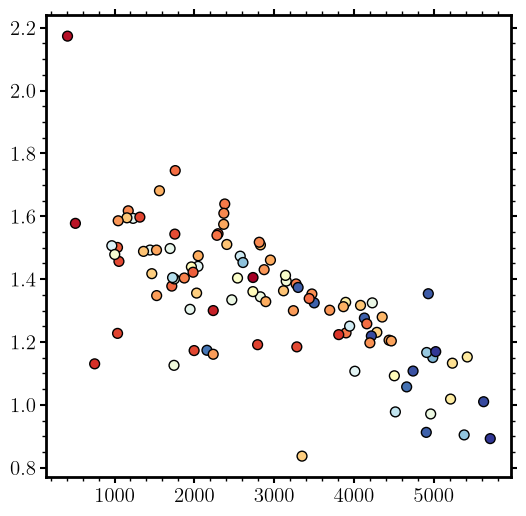

In [12]:
plt.scatter(speeds['CIV_blue0'], np.log10(speeds['CIV_EW0']), c=speeds['EHVO_vmax'], # VMAX
            zorder=100, cmap='RdYlBu_r', edgecolor='k', s=50)
xlims = plt.gca().get_xlim()
ylims = plt.gca().get_ylim()

In [13]:
# remove crazy high EW EHVO
speeds.remove_row(np.where(np.log10(speeds['CIV_EW0']) > 2.1)[0][0])

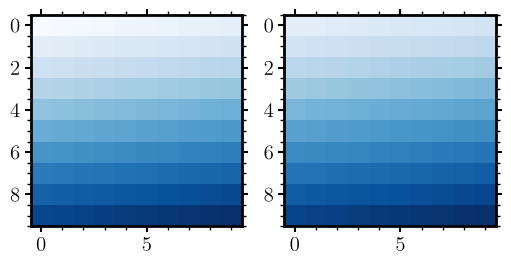

In [14]:
colormap='Blues'
import matplotlib.colors as colors

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)

cmap = plt.get_cmap(colormap)
new_cmap = truncate_colormap(cmap, 0.1, 1)
ax[0].imshow(arr, interpolation='nearest', cmap=cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=new_cmap)
plt.show()

# Vmax


(array([ 3., 17., 42., 55., 62., 78., 83., 87., 88., 99.]),
 array([34.61891843, 37.15635964, 39.69380084, 42.23124205, 44.76868326,
        47.30612446, 49.84356567, 52.38100688, 54.91844809, 57.45588929,
        59.9933305 ]),
 <BarContainer object of 10 artists>)

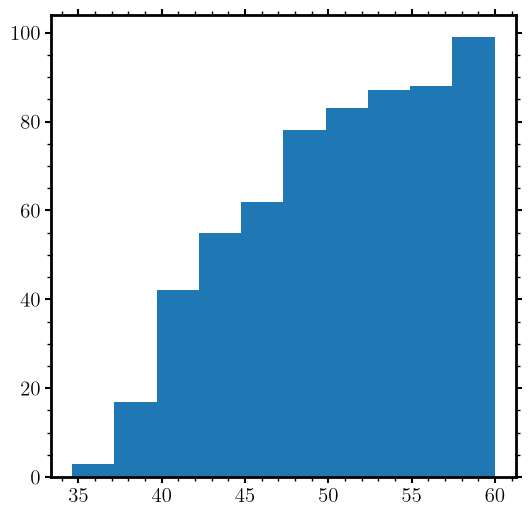

In [15]:
plt.hist(-speeds['EHVO_vmax']/1e3, cumulative=True)

In [16]:
minvmax, maxvmax = np.min(-speeds['EHVO_vmax']/1e3), np.max(-speeds['EHVO_vmax']/1e3)
vmax = qso['BI_VMAX'][inds]

vmax[vmax < np.percentile(vmax, 5)] = np.percentile(vmax, 5)
vmax[vmax > np.percentile(vmax, 95)] = np.percentile(vmax, 95)


In [17]:
min(vmax), max(-speeds['EHVO_vmax'])

(np.float64(5443.082244861084), np.float64(59993.3305))

In [18]:
vmax = vmax/10**3

# Vmin


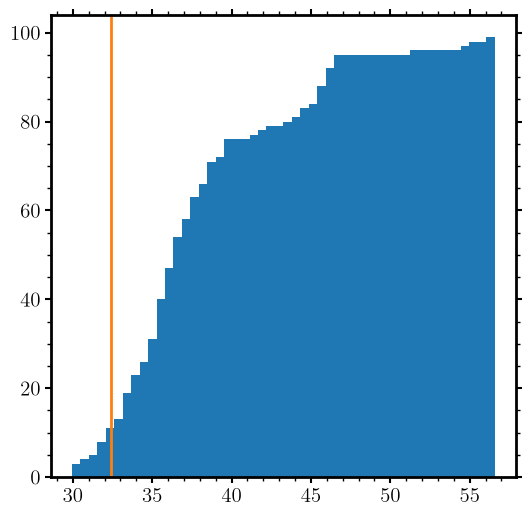

In [19]:
plt.hist(-speeds['EHVO_vmin']/1e3, 50, cumulative=True)
plt.axvline(np.percentile(-speeds['EHVO_vmin']/1e3, 10), c='C1')

In [20]:
np.percentile(-speeds['EHVO_vmin']/1e3, 10)

np.float64(32.388431318)

In [21]:
vmin = qso['BI_VMIN'][inds] / 10**3
#minvmin, maxvmin = np.percentile(-speeds['EHVO_vmin']/1e3, 1), 50
minvmin, maxvmin = np.min(-speeds['EHVO_vmin']/1e3), np.max(-speeds['EHVO_vmin']/1e3)
minvmin, maxvmin

(np.float64(29.95332707), np.float64(56.57732957))

In [22]:
vmin[vmin > np.percentile(vmin, 90)] = np.percentile(vmin, 90)

In [23]:
# BAL or non-BAL in Rankine+20
nb = speeds['nBAL0'] == 'True'
b = speeds['BAL0'] == 'True'
# bal = np.zeros(len(ehvo), 'bool')
# bal[~ehvo['Qinds'].mask][qso['BI_BI'][ehvo['Qinds'][~ehvo['Qinds'].mask]] > 0] = 1
# bal
sum(b), sum(nb)

(np.int64(23), np.int64(76))

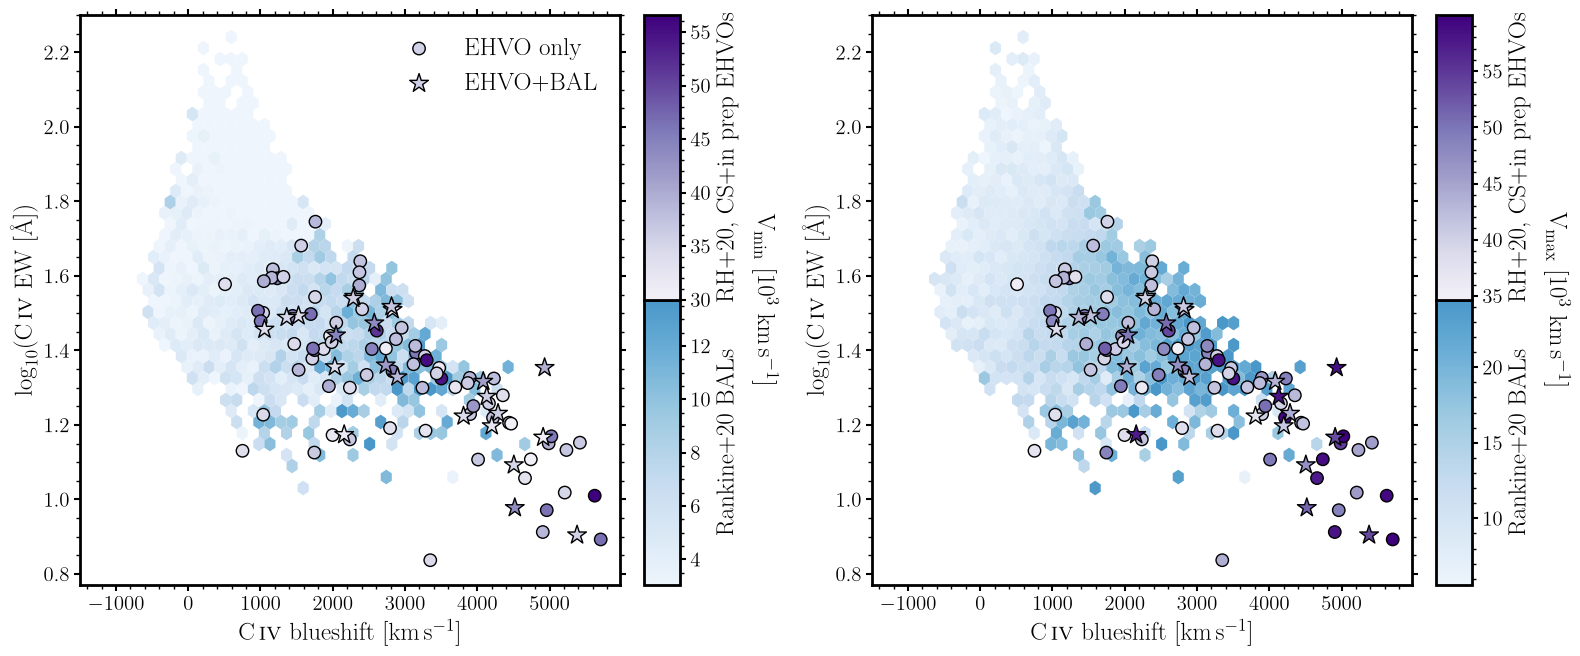

In [27]:
fig = plt.figure(figsize=(12, 6))
x0 = 0.05
y0 = 0.05
xw = 0.45
yh = 0.95

ygap = 0.16

cw = 0.03
cgap = 0.02

axmin = fig.add_axes([x0, y0, xw, yh])

cax1min = fig.add_axes([x0 + xw + cgap, y0, cw, yh/2])

cax2min = fig.add_axes([x0 + xw + cgap, y0 + yh/2, cw, yh/2])

axmax = fig.add_axes([x0 + xw + cgap + cw + ygap, y0, xw, yh], sharex=axmin, sharey=axmin)

cax1max = fig.add_axes([x0 + xw + cgap + cw + ygap + xw + cgap, y0, cw, yh/2])

cax2max = fig.add_axes([x0 + xw + cgap + cw + ygap + xw + cgap, y0 + yh/2, cw, yh/2])

axmin.set_xlim(min([-1500, xlims[0]]), max([5000, xlims[1]]))
axmin.set_ylim(min([1, ylims[0]]), max([2.3, ylims[1]]))
axmin.set_xlabel(CIVx)
axmin.set_ylabel(CIVy)
axmax.set_xlabel(CIVx)
axmax.set_ylabel(CIVy)

fig.text(x0 + xw + cgap + cw + 0.06, y0 + yh/2, r'V$_{\text{min}}$ [$10^3$ km\,s$^{-1}$]', 
         rotation=270, fontsize=18, va='center', ha='left')

fig.text(x0 + xw + cgap + cw + ygap + xw + cgap+ cw + 0.06, y0 + yh/2, r'V$_{\text{max}}$ [$10^3$ km\,s$^{-1}$]', 
         rotation=270, fontsize=18, va='center', ha='left')



#### VMIN #####
new_cmap = truncate_colormap(cmap, 0.05, 0.6)
cm=axmin.hexbin(qso['CIV_blue_eun'][inds], np.log10(qso['CIV_EW_eun'][inds]),
                                         gridsize=50,
                                         C=vmin,
                                         cmap=new_cmap,
                                         reduce_C_function=np.median, mincnt=4,
                                         vmin=None, vmax=None,#vmin[i], vmax=vmax[i],
                                         edgecolor=None, zorder=99)

cbar = plt.colorbar(cm, cax=cax1min)
# print(cbar.ax.get_yticklabels())
# cbar.ax.set_yticks(cbar.ax.get_yticks()[1:-2])#(MaxNLocator(prune='both'))
cbar.set_label('Rankine+20 BALs')

cmeh = axmin.scatter(speeds['CIV_blue0'][nb], np.log10(speeds['CIV_EW0'][nb]), c=-speeds['EHVO_vmin'][nb]/1e3, 
                     zorder=100, cmap=truncate_colormap(plt.get_cmap('Purples'), 0.1, 1), 
                     edgecolor='k', s=80,
                     vmin=minvmin, vmax=maxvmin, label='EHVO only')

cmeh = axmin.scatter(speeds['CIV_blue0'][b], np.log10(speeds['CIV_EW0'][b]), c=-speeds['EHVO_vmin'][b]/1e3, 
                     zorder=100, cmap=truncate_colormap(plt.get_cmap('Purples'), 0.1, 1), 
                     edgecolor='k', s=200, marker='*',
                     vmin=minvmin, vmax=maxvmin, label='EHVO+BAL')


cbareh = plt.colorbar(cmeh, cax=cax2min)
cbareh.set_label(r'RH+20, CS+in prep EHVOs')

axmin.legend()

#### VMAX #####
#new_cmap = truncate_colormap(cmap, 0.1, 1)
cm=axmax.hexbin(qso['CIV_blue_eun'][inds], np.log10(qso['CIV_EW_eun'][inds]),
                                         gridsize=50,
                                         C=vmax,
                                         cmap=new_cmap,
                                         reduce_C_function=np.median, mincnt=4,
                                         vmin=None, vmax=None,#vmin[i], vmax=vmax[i],
                                         edgecolor=None, zorder=99)


cbar = plt.colorbar(cm, cax=cax1max)
cbar.set_label('Rankine+20 BALs')

#edgecolorn = ['w' if v/1e3 > 50 else 'k' for v in -speeds['VMAXz'][nb]]
#edgecolorb = ['w' if v/1e3 > 50 else 'k' for v in -speeds['VMAXz'][b]]

cmeh = axmax.scatter(speeds['CIV_blue0'][nb], np.log10(speeds['CIV_EW0'][nb]), c=-speeds['EHVO_vmax'][nb]/1e3, 
                     zorder=100, cmap=truncate_colormap(plt.get_cmap('Purples'), 0.1, 1), 
                     edgecolor='k', 
                     s=80,
                     vmin=minvmax, vmax=maxvmax)

cmeh = axmax.scatter(speeds['CIV_blue0'][b], np.log10(speeds['CIV_EW0'][b]), c=-speeds['EHVO_vmax'][b]/1e3, 
                     zorder=100, cmap=truncate_colormap(plt.get_cmap('Purples'), 0.1, 1), 
                     edgecolor='k', 
                     s=200, marker='*',
                     vmin=minvmax, vmax=maxvmax)

cbareh = plt.colorbar(cmeh, cax=cax2max)
cbareh.set_label(r'RH+20, CS+in prep EHVOs')

plt.savefig('CIV_vmin_vmax_Rankine_crange.pdf')